# Example 1.3 — Coupling Curve of a Four-Bar Mechanism
**Four Bar Mechanisms: Synthesis with Genetic Algorithms and Neural Networks**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/)

---
## Statement
For the mechanism with:
- $a = 50$ mm (crank)
- $b = 120$ mm (connecting rod / coupler)
- $c = 80$ mm (rocker arm)
- $d = 100$ mm (frame)

Calculate and graph the trajectory of the coupling point located at $p = 40$ mm and $\delta = 30°$ from the connecting rod,
turning the crank 360°.

## Theoretical foundation
The **Freudenstein equations** allow solving the position of the four-bar mechanism.
Defining the constants:

$$K_1 = \frac{d}{a}, \quad K_2 = \frac{d}{c}, \quad K_3 = \frac{a^2 - b^2 + c^2 + d^2}{2ac}$$

$$K_4 = \frac{d}{b}, \quad K_5 = \frac{c^2 - d^2 - a^2 - b^2}{2ab}$$

The position of the coupling point $P$ is:

$$P_x = a\cos\theta_2 + p\cos(\theta_3 + \delta)$$
$$P_y = a\sin\theta_2 + p\sin(\theta_3 + \delta)$$

where $\theta_2$ is the crank angle, $\theta_3$ is the connecting rod angle,
$p$ is the distance to the coupler point, and $\delta$ is its angular offset.

In [ ]:
from numpy import *

def fourbar_pos(a, b, c, d, th2):
    """Returns th3, th4 for crank angle th2 (rad)."""
    K1 = d/a; K2 = d/c; K3 = (a**2-b**2+c**2+d**2)/(2*a*c)
    K4 = d/b; K5 = (c**2-d**2-a**2-b**2)/(2*a*b)
    A = cos(th2) - K1 - K2*cos(th2) + K3
    B = -2*sin(th2)
    C = K1 - (K2+1)*cos(th2) + K3
    disc = B**2 - 4*A*C
    mask = disc >= 0
    th4 = full_like(th2, nan)
    th4[mask] = 2*arctan2(-B[mask] - sqrt(disc[mask]), 2*A[mask])
    A2 = cos(th2) - K1 + K4*cos(th2) + K5
    B2 = -2*sin(th2)
    C2 = K1 + (K4-1)*cos(th2) + K5
    disc2 = B2**2 - 4*A2*C2
    th3 = full_like(th2, nan)
    th3[mask] = 2*arctan2(-B2[mask] - sqrt(disc2[mask]), 2*A2[mask])
    return th3, th4

a, b, c, d = 50., 120., 80., 100.
p, delta = 40., radians(30.)
th2 = linspace(0, 2*pi, 360)
th3, th4 = fourbar_pos(a, b, c, d, th2)

# Coupler point position
Px = a*cos(th2) + p*cos(th3 + delta)
Py = a*sin(th2) + p*sin(th3 + delta)

valid = isfinite(Px)
print(f"Valid points of the coupler curve: {valid.sum()} / {len(th2)}")
print(f"X span: [{nanmin(Px):.1f}, {nanmax(Px):.1f}] mm")
print(f"Y span: [{nanmin(Py):.1f}, {nanmax(Py):.1f}] mm")

Valid points of the coupler curve: 360 / 360
X span: [-32.9, 75.1] mm
Y span: [-10.3, 77.7] mm


## Display
The following block plots the complete coupling curve and the mechanism at the position $\theta_2 = 180°$.

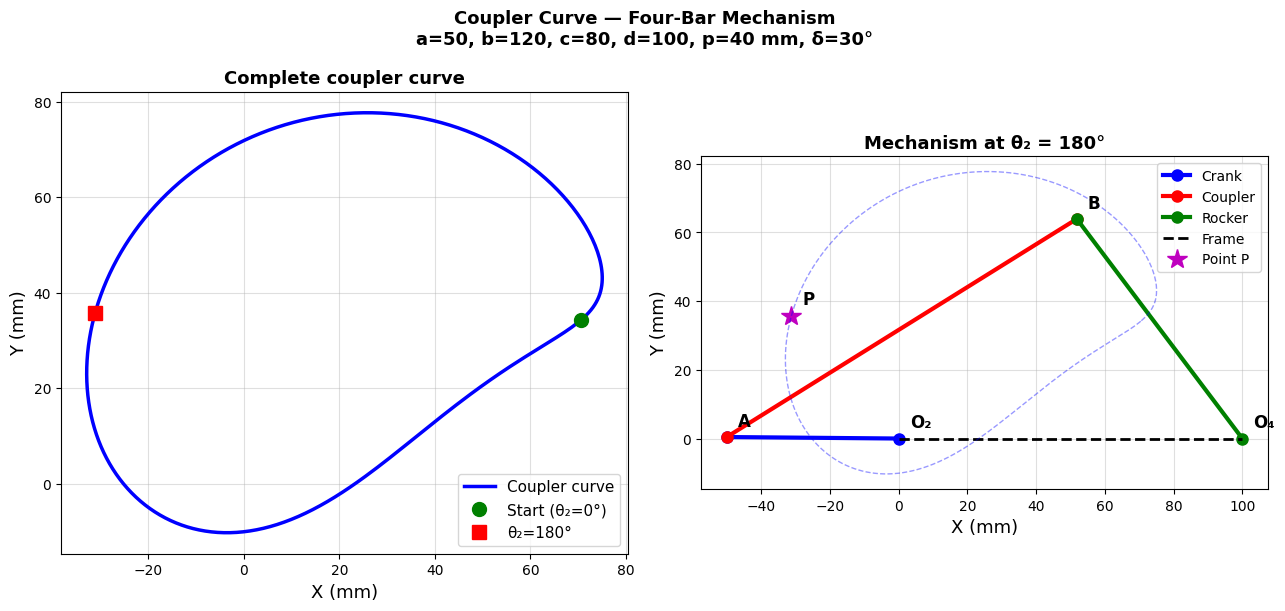

Figure saved as coupler_curve.png


In [ ]:
from numpy import *
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

def fourbar_pos_np(a, b, c, d, th2):
    K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
    K4=d/b; K5=(c**2-d**2-a**2-b**2)/(2*a*b)
    A=cos(th2)-K1-K2*cos(th2)+K3
    B=-2*sin(th2)
    C=K1-(K2+1)*cos(th2)+K3
    disc=B**2-4*A*C; mask=disc>=0
    th4=full_like(th2,nan)
    th4[mask]=2*arctan2(-B[mask]-sqrt(disc[mask]),2*A[mask])
    A2=cos(th2)-K1+K4*cos(th2)+K5
    B2=-2*sin(th2)
    C2=K1+(K4-1)*cos(th2)+K5
    disc2=B2**2-4*A2*C2; th3=full_like(th2,nan)
    th3[mask]=2*arctan2(-B2[mask]-sqrt(disc2[mask]),2*A2[mask])
    return th3,th4

a,b,c,d=50.,120.,80.,100.
p,delta=40.,radians(30.)
th2=linspace(0,2*pi,360)
th3,th4=fourbar_pos_np(a,b,c,d,th2)
Px=a*cos(th2)+p*cos(th3+delta)
Py=a*sin(th2)+p*sin(th3+delta)

fig, (ax1,ax2)=plt.subplots(1,2,figsize=(13,6))

# Coupling curve
ax1.plot(Px,Py,'b-',lw=2.5,label='Coupler curve')
ax1.plot(Px[0],Py[0],'go',ms=10,label='Start (θ₂=0°)')
ax1.plot(Px[179],Py[179],'rs',ms=10,label='θ₂=180°')
ax1.set_xlabel('X (mm)',fontsize=13); ax1.set_ylabel('Y (mm)',fontsize=13)
ax1.set_title('Complete coupler curve',fontsize=13,fontweight='bold')
ax1.legend(fontsize=11); ax1.grid(True,alpha=0.4); ax1.set_aspect('equal')

# Mechanism at θ₂=180°
i=179
O2=array([0.,0.]); O4=array([d,0.])
A_pt=array([a*cos(th2[i]),a*sin(th2[i])])
B_pt=array([d+c*cos(th4[i]),c*sin(th4[i])])
P_pt=array([Px[i],Py[i]])
ax2.plot(*zip(O2,A_pt),'b-o',lw=3,ms=8,label='Crank')
ax2.plot(*zip(A_pt,B_pt),'r-o',lw=3,ms=8,label='Coupler')
ax2.plot(*zip(B_pt,O4),'g-o',lw=3,ms=8,label='Rocker')
ax2.plot(*zip(O2,O4),'k--',lw=2,label='Frame')
ax2.plot(*P_pt,'m*',ms=15,label='Point P')
ax2.plot(Px,Py,'b--',lw=1,alpha=0.4)
for pt,name in [(O2,'O₂'),(O4,'O₄'),(A_pt,'A'),(B_pt,'B'),(P_pt,'P')]:
    ax2.annotate(name,pt,textcoords='offset points',xytext=(8,8),fontsize=12,fontweight='bold')
ax2.set_xlabel('X (mm)',fontsize=13); ax2.set_ylabel('Y (mm)',fontsize=13)
ax2.set_title('Mechanism at θ₂ = 180°',fontsize=13,fontweight='bold')
ax2.legend(fontsize=10); ax2.grid(True,alpha=0.4); ax2.set_aspect('equal')

plt.suptitle('Coupler Curve — Four-Bar Mechanism\n'
             'a=50, b=120, c=80, d=100, p=40 mm, δ=30°',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('coupler_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as coupler_curve.png')